# **Airborne Object Tracking Introspection Module Evaluation**

## **1. Overview**

This notebook evaluates the introspective self-monitoring layer built on top of the HRNet-W32 Tracking-to-Detect (T2D) pipeline, for the [AICrowd Airborne Object Tracking Challenge](https://www.aicrowd.com/challenges/airborne-object-tracking-challenge), a benchmark designed for long-range airborne object detection and tracking in autonomous Sense & Avoid (SAA) systems. Autonomous SAA systems are responsible for maintaining safe separation between aircraft and unforeseen obstacles during flight. While flight paths may be planned in advance, real-world operation in unconstrained airspace introduces the possibility of encountering unexpected airborne objects. In such cases, the system must perform situational awareness, decision-making, and evasive manoeuvre planning in real time. 

The primary objective of this notebook is to evaluate **introspection strategies** layered on top of a fixed HRNet-W32 Tracking-to-Detect (T2D) backbone. Rather than comparing alternative detection backbones, each introspection strategy monitors the output of the existing tracking pipeline and determines, on a per-track and per-frame basis, whether tracking quality is degrading. The underlying detection and tracking pipeline remains unchanged throughout all experiments, ensuring that any differences in performance are attributable solely to the introspection module.

### **1.1. Example Airborne Encounter**

<div align="center">
  <img src="../docs/Images/Data_Viewer_Video.gif" width="700"/>
</div>

<p align="center">
  <em>Example Airborne Encounter from the Evaluation Dataset. The Target Aircraft Occupies Only a Few Pixels During the Early Stages of the Encounter.</em>
</p>


---

## **2. Introspection Modules Evaluated**

* **Default Condition:** Never raises a flag. Used to verify that the introspective wrapper produces results identical to the baseline T2D pipeline.
* **Simple Confidence Threshold:** Flags a track as unreliable when its detection confidence remains below a fixed threshold for a specified number of consecutive frames. Serves as the simplest interpretable baseline.

<div style="background-color:#fff8dc; border-left:5px solid #f0c419; padding:10px 15px; margin:10px 0;"> <strong>⚠️ PLACEHOLDER - Additional introspection modules will be added.</strong><br/> Update this section to include all implemented modules once development and evaluation are complete. </div>


---

## **3. Evaluation Metrics**

* **AFDR:** Average Frame Detection Rate.
* **CEDR:** Continuous Encounter Detection Rate.
* **FTPS:** False Tracks Per Sequence.

> ⚠️ ***Note:*** *Inference for all models requires a CUDA-capable GPU. While CPU-based loading of model weights is supported for inspection, full evaluation is computationally intensive.*

<div style="background-color:#fff8dc; border-left:5px solid #f0c419; padding:10px 15px; margin:10px 0;">
<strong>⚠️ PLACEHOLDER - Introspection-specific failure detection metrics are to be determined.</strong></br>
Populate this section once the evaluation protocol has been finalised.
</div>



---

## **4. Dataset**

The custom dataset used in this notebook is a curated hard subset of the full Airborne Object Tracking (AOT) dataset, specifically designed to stress-test model performance under the most demanding real-world conditions. Flights were selected to isolate encounters that represent the greatest challenge for vision-based detection and tracking systems.

### **4.1. Example Detection Progression**
<div align="center" style="display: flex; justify-content: center; gap: 20px;">
  <div style="text-align: center;">
    <img src="../docs/Images/Data_Viewer_Picture_1.png" width="650"/>
    <p><em>Early Detection</em></p>
  </div>
  <div style="text-align: center;">
    <img src="../docs/Images/Data_Viewer_Picture_2.png" width="650"/>
    <p><em>Closing Distance</em></p>
  </div>
  <div style="text-align: center;">
    <img src="../docs/Images/Data_Viewer_Picture_3.png" width="650"/>
    <p><em>Near Range</em></p>
  </div>
</div>

*The sequence above demonstrates how airborne targets gradually increase in apparent size throughout an encounter. Reliable early detection is particularly challenging because aircraft often occupy only a few pixels during the most safety-critical phase of the encounter.*

<br/>

### **4.2. Hard Subset Selection Criteria**

- **Small Targets:** Airborne objects occupying only a few pixels per frame.
- **Multiple Targets:** Scenes containing more than one airborne object simultaneously.
- **Poor Visibility:** Flights affected by sun glare, adverse lighting, or challenging camera angles.

<br/>

### **4.3. Dataset Summary**

The dataset is partitioned into a stratified 70/15/15 train/validation/test split to preserve the distribution of key difficulty factors across all subsets.

<div align="center">

<table>
  <thead>
    <tr>
      <th>Metric</th>
      <th>Value</th>
      <th>Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><strong>Total Flights</strong></td>
      <td><strong>1618</strong></td>
      <td><strong>Total number of flight sequences in the dataset.</strong></td>
    </tr>
    <tr>
      <td>Small Object Flights</td>
      <td>662</td>
      <td>Flights containing at least one object with bounding box area ≤ 36.0px².</td>
    </tr>
    <tr>
      <td>Below Horizon Flights</td>
      <td>1053</td>
      <td>Flights containing at least one object at or below the horizon.</td>
    </tr>
    <tr>
      <td>Multi-Object Flights</td>
      <td>627</td>
      <td>Flights containing more than one airborne object in at least one frame.</td>
    </tr>
    <tr>
      <td>No Object Frames</td>
      <td>354</td>
      <td>Flights containing at least one frame with no airborne object present.</td>
    </tr>
    <tr>
      <td><em>Avg. Sequence Length</em></td>
      <td><em>17.77s</em></td>
      <td><em>Average duration of each flight sequence.</em></td>
    </tr>
  </tbody>
</table>

</div>


<div style="background-color:#fff8dc; border-left:5px solid #f0c419; padding:10px 15px; margin:10px 0;">
<strong>⚠️ PLACEHOLDER - Evaluation currently uses the unmodified AOT held-out test set. </strong><br/>
A controlled degradation benchmark, based on the AOT-C corruption protocol, remains under consideration and has not yet been implemented. Refer to the project notes for additional discussion.
</div>


---

<br/>

In [1]:
# Import Required Libraries.
import os
import sys

import cv2
import json
import torch
import random

from glob import glob
import matplotlib.pyplot as plt

# Because Life, Universe & Everything!
random.seed(42)

# Set Working Directory to Project Root.
os.chdir("..") 
PROJECT_ROOT = os.getcwd()

# Add Project Root to Path.
sys.path.insert(0, PROJECT_ROOT)

# Add Core Metric Folders to System Path.
sys.path.insert(0, os.path.join(PROJECT_ROOT, "core"))

# Import Local Project Funtions.
from logging_module import LogLevel, log
from src.data.download_data import main as downloadData
from notebooks.helpers.notebook_visualiser import main as visualise_results
from notebooks.helpers.notebook_helpers import (
    get_next_run_dir, load_combined_gt, resolve_local_flights,
    convert_results_to_metrics_format, measure_predictor_complexity, 
    display_styled_summary, build_introspection_summary
)
 
# Confirm Project Root.
log(LogLevel.INFO, "introspection_module:imports", "Project Root Set: %s", PROJECT_ROOT)

<INFO ><introspection_module:imports> Project Root Set: /home/busatmd021/projects/2026/Vision-Based-Sense-and-Avoid


In [2]:
# Choose Which Introspection Module to Run
# --------------------------------------------------
# 0 -> None (Control Condition -- Plain T2D, Escalation Never Fires).
# 1 -> Confidence Threshold (Simple Baseline).
SELECTED_INTROSPECTION_MODULE = 0
module_list = ["none", "confidence_threshold"]

# Evaluation Filtering.
MIN_SCORE = 0.60
DETECTION_THRESHOLD = 0.60
MIN_TRACK_LEN = 30

# Set Path to Desired Evaluation Dataset.
DATASET_PATH = "configs/datasets/training_subsets/test.txt"
DATASET_PARTS = ["part1", "part2", "part3"]

# Set Results Variables (Auto-Incrementing Run Directory).
RESULTS_DIR = "outputs/results/introspection_module/" + module_list[SELECTED_INTROSPECTION_MODULE]
run_name = get_next_run_dir(RESULTS_DIR)

# Evaluation Output Folders.
EVAL_GT_DIR = os.path.join(RESULTS_DIR, run_name, "gt")
EVAL_RESULT_DIR  = os.path.join(RESULTS_DIR, run_name, "result")
EVAL_SUMMARY_DIR = os.path.join(RESULTS_DIR, run_name, "summaries")

# Print Summary Statement.
log(LogLevel.INFO, "introspection_module:config", "Configuration Loaded.")
print(f"  Introspection Module : {module_list[SELECTED_INTROSPECTION_MODULE]}")
print(f"  Dataset Path         : {DATASET_PATH}")
print(f"  Dataset Parts        : {DATASET_PARTS}")
print(f"  Run Name             : {run_name}")
print(f"  Results Path         : {RESULTS_DIR}")
print(f"  Min Score            : {MIN_SCORE}")
print(f"  Min Track Len        : {MIN_TRACK_LEN}")

<INFO ><introspection_module:config> Configuration Loaded.
  Introspection Module : none
  Dataset Path         : configs/datasets/training_subsets/test.txt
  Dataset Parts        : ['part1', 'part2', 'part3']
  Run Name             : run2
  Results Path         : outputs/results/introspection_module/none
  Min Score            : 0.6
  Min Track Len        : 30


In [ ]:
# Download the Selected Flight Sequences.
downloadData(DATASET_PATH)


---

<br/>

## **5. Data Preparation & Preprocessing**

Before inference can begin, the dataset must be resolved from the flight ID list down to what is actually available on disk, and the ground truth must be filtered to match. This cell performs two steps:

**5.1. Flight Resolution:** Parses the `.txt` flight ID file produced by `data_builder.py`, cross-references each entry against the local `data/<part>/Images/` directories, and builds a lookup of every flight that is both listed and downloaded. Flights in the list that have not been downloaded are logged and skipped.

**5.2. Ground Truth Filtering:** Loads the `groundtruth.json` file from each part's `ImageSets/` folder and merges them into a single structure, retaining only the entries that correspond to locally available flights. Entries for flights not on disk are silently skipped - this is expected, as the ground truth files reference the full AOT dataset rather than just the downloaded subset.

In [3]:
# Find all Available Sequences from the Provided Dataset.
local_flights = resolve_local_flights(DATASET_PATH, PROJECT_ROOT)

# Add Spacing in Console Output for Readability.
print()

# Log How Many Flights were Found & are Ready for Inference.
log(LogLevel.INFO, "introspection_module:preprocessing", "Flights Ready for Inference: %d", len(local_flights))

# Preview the First 5 Flights to Confirm Dataset is Correct.
for name, info in list(local_flights.items())[:5]:
    # Count No. Images in the Flight Directory.
    n_imgs = len(list(info["images_dir"].glob("*.png")))

    # Print Flight Part, Name, & No. Images.
    print(f"  [{info['part']}]  {name}  ({n_imgs} images)")

# If there are More than 5 Flights, Log How Many Additional Ones Exist.
if len(local_flights) > 5:
    log(LogLevel.DEBUG, "introspection_module:preprocessing", " ... and %d more.", len(local_flights) - 5)

# Load & Filter Ground Truth to Include Local Flights Only. 
combined_gt = load_combined_gt(DATASET_PARTS, local_flights, PROJECT_ROOT)
log(LogLevel.INFO, "introspection_module:preprocessing", "Flights in Filtered Ground Truth: %d", len(combined_gt['samples']))

# Build Set of Image Filenames That Physically Exist on Disk.
all_images = {name for f in local_flights.values() for name in f["image_names"]}

# Cull GT Entities to Only Those With a Corresponding Image on Disk.
before = sum(len(flight["entities"]) for flight in combined_gt["samples"].values())

for flight_hash, flight_data in combined_gt["samples"].items():
    flight_data["entities"] = [
        e for e in flight_data["entities"]
        if e["img_name"] in all_images
    ]

after = sum(len(flight["entities"]) for flight in combined_gt["samples"].values())

# Report How Many Images were Removed. 
log(LogLevel.INFO, "introspection_module:preprocessing",
    "GT Culled: %d -> %d entities (%d removed for missing images).", before, after, before - after)

# Save the Filtered Ground Truth to the Evaluation Folder.
os.makedirs(EVAL_GT_DIR, exist_ok=True)
gt_out_path = os.path.join(EVAL_GT_DIR, "groundtruth.json")

# Copy the Ground Truth Values to the .json.
with open(gt_out_path, "w") as f:
    json.dump(combined_gt, f)

# Print Success Message.
log(LogLevel.INFO, "introspection_module:preprocessing", "Ground Truth Saved: %s", gt_out_path)

<INFO ><notebook_helpers:resolve_flights> 2 Flights on Disk. 0 Not Found. (Run the Download Cell to Fetch Missing Flights).

<INFO ><introspection_module:preprocessing> Flights Ready for Inference: 2
  [part1]  part11b3a52c0f1764533b32e36992b17b6e1  (1198 images)
  [part1]  part1036edfd6ece44c37b8ca9562fd701682  (1199 images)

<INFO ><notebook_helpers:load_gt> 2 kept / 4154 total.
<INFO ><introspection_module:preprocessing> Flights in Filtered Ground Truth: 2
<INFO ><introspection_module:preprocessing> GT Culled: 2838 -> 2838 entities (0 removed for missing images).
<INFO ><introspection_module:preprocessing> Ground Truth Saved: outputs/results/introspection_module/none/run2/gt/groundtruth.json



---

<br/>

## **6. Evaluate Models**

### **6.1. Run Inference**

This section runs inference for the selected backbone configuration. The evaluation is controlled via the `SELECTED_MODEL` parameter, which determines which backbone is instantiated and evaluated within the shared detection pipeline. All models are evaluated under a consistent inference setup to ensure fair comparison across backbone architectures, using the same preprocessing, detection pipeline, and evaluation metrics.

<br/>

#### **6.1.1. Prepare Evaluation Directory & Configure Environment Variables.**

In [4]:
# Create a Directory where all Evaluation Flight Data will be Stored.
EVAL_DATA_DIR = os.path.join(RESULTS_DIR, run_name, "data")
os.makedirs(EVAL_DATA_DIR, exist_ok=True)

# Link Each Local Flight's Image Folder into the Evaluation Directory.
for folder_name, info in local_flights.items():
    link_path = os.path.join(EVAL_DATA_DIR, folder_name)
    if not os.path.exists(link_path):
        os.symlink(info["images_dir"], link_path)

# Set Environment Variables that AirbornePredictor and SelectedModelPredictor Read.
os.environ["TEST_DATASET_PATH"] = EVAL_DATA_DIR
os.environ["INFERENCE_OUTPUT_PATH"] = RESULTS_DIR
os.environ["DATASET_ENV"] = run_name
os.environ["MIN_TRACK_LEN"] = str(MIN_TRACK_LEN)
os.environ["MIN_SCORE"] = str(MIN_SCORE)
os.environ["DETECTION_THRESHOLD"] = str(DETECTION_THRESHOLD)

# Disable the Per-Flight Timeout.
os.environ["INFERENCE_PER_FLIGHT_TIMEOUT_SECONDS"] = "0"

# Limit Inference to Only the Specified Flights.
os.environ["PARTIAL_RUN_FLIGHTS"] = ",".join(local_flights.keys())

# Print Summary Statement.
log(LogLevel.INFO, "introspection_module:inference", "Environment Configured.")
print(f"  Test Data Path     : {EVAL_DATA_DIR}")
print(f"  Flights to Process : {len(local_flights)}")
print(f"  MIN_SCORE          : {MIN_SCORE}")
print(f"  MIN_TRACK_LEN      : {MIN_TRACK_LEN}")

<INFO ><introspection_module:inference> Environment Configured.
  Test Data Path     : outputs/results/introspection_module/none/run2/data
  Flights to Process : 2
  MIN_SCORE          : 0.6
  MIN_TRACK_LEN      : 30



<br/>

#### **6.1.2. Run Model Inference Across All Evaluation Flights Using the Selected Configuration.**

> ⚠️ ***This cells requires a CUDA GPU and will take several hours to complete.*** *Skip this cell if inference has already been run and results are present in `RESULTS_DIRS`.*

In [6]:
# Import the Introspective Predictor Class & the Introspection Module Registry.
from src.introspection_module.hrnetw32_introspective.hrnetw32_introspective_test import HRNetW32IntrospectivePredictor
from src.introspection_module.hrnetw32_introspective.introspection_modules import INTROSPECTION_MODULE_MAP

# Check GPU is CUDA Enabled.
if torch.cuda.is_available():
    log(LogLevel.INFO, "introspection_module:device_check", "CUDA-Enabled GPU is Available.")
    print(f"  GPU Name: {torch.cuda.get_device_name(0)}.")
    print(f"  CUDA Version: {torch.version.cuda}.")
else:
      log(LogLevel.WARNING, "introspection_module:device_check", "No CUDA-Enabled GPU Found, Using CPU Instead.")

<INFO ><introspection_module:device_check> CUDA-Enabled GPU is Available.
  GPU Name: NVIDIA GeForce RTX 5060 Ti.
  CUDA Version: 12.8.


In [7]:
# Validate Selection.
if SELECTED_INTROSPECTION_MODULE not in INTROSPECTION_MODULE_MAP:
    log(LogLevel.ERROR, "introspection_module:inference", "Invalid SELECTED_INTROSPECTION_MODULE: %s.", SELECTED_INTROSPECTION_MODULE)
    raise ValueError("Please Select a Valid Introspection Module Index.")

# Instantiate the Selected Introspection Module.
introspection_module = INTROSPECTION_MODULE_MAP[SELECTED_INTROSPECTION_MODULE]()

# Initialise the Predictor & Inject the Selected Introspection Module
# BEFORE inference_setup() Runs.
predictor = HRNetW32IntrospectivePredictor()
predictor.introspection_module = introspection_module

# Load Models Before Measuring Complexity.
predictor.inference_setup()

# Measure the Current Model's Complexity.
print()
complexity = measure_predictor_complexity(predictor)

# Run Inference Over all Flights.
print()
predictor.run()

# Print Summary Statement.
log(LogLevel.INFO, "introspection_module:inference", "Inference Complete.")
print(f"  Raw Results Saved to: {os.path.join(RESULTS_DIR, run_name)}\n")

# Set Results Directories. 
RAW_RESULTS_PATH = os.path.join(RESULTS_DIR, run_name, "result.json")
METRICS_RESULTS_PATH = os.path.join(EVAL_RESULT_DIR, "result.json")

# Ensure Output Directory Exists.
os.makedirs(EVAL_RESULT_DIR, exist_ok=True)

# Copy the Results File.
convert_results_to_metrics_format(RAW_RESULTS_PATH, METRICS_RESULTS_PATH)

# Print Summary Statement.
log(LogLevel.INFO, "introspection_module:inference", "Results Copied to Metrics Directory.")
print(f"  Metrics-Ready Results Stored at : {METRICS_RESULTS_PATH}")

<INFO ><hrnetw32_ttd:inference_setup> Segmentation Weights Loaded: configs/models/core_improvement/hrnetw32/HRNetW32_Complete.pt
<INFO ><hrnetw32_ttd:inference_setup> Transform Model Loaded.
<INFO ><hrnetw32_ttd:inference_setup> HRNetW32TrackToDetectPredictor Ready.

<INFO ><hrnetw32_introspective:inference_setup> Introspection Module 'none' Selected. Ensemble NOT Loaded.
<INFO ><hrnetw32_introspective:inference_setup> HRNetW32IntrospectivePredictor Ready (Introspection: none).

<INFO ><notebook_helpers:measure_complexity> [HRNet-W32 (segmentation)] Params: 29,559,440 total / 29,559,440 trainable | GFLOPs: 42.451 | GMACs: 21.226
<INFO ><notebook_helpers:measure_complexity> [ResNet34-TSM Transform (model_transform)] Params: 21,281,475 total / 21,281,475 trainable | GFLOPs: 150.135 | GMACs: 75.067
<INFO ><notebook_helpers:measure_predictor_complexity> Total - Params: 50,840,915 | GFLOPs: 192.586 | GMACs: 96.293

<INFO ><hrnetw32_ttd:inference_setup> Segmentation Weights Loaded: configs/m

Flight part11b3a52c0f1764533b32e36992b17b6e1:   0%|          | 1/1198 [00:00<03:56,  5.07it/s]Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices": 0, "best_kernel": "bias_addmm", "best_time": 0.014336000196635723}
AUTOTUNE addmm(784x2, 784x1024, 1024x2)
strides: [0, 1], [1024, 1], [1, 1024]
dtypes: torch.float16, torch.float16, torch.float16
  bias_addmm 0.0143 ms 100.0% 
  addmm 0.0165 ms 86.7% 
SingleProcess AUTOTUNE benchmarking takes 0.1594 seconds and 0.0001 seconds precompiling for 2 choices
Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices": 0, "best_kernel": "bias_addmm", "best_time": 0.8653439879417419}
AUTOTUNE addmm(81920x512, 81920x480, 480x512)
strides: [0, 1], [480, 1], [1, 480]
dtypes: torch.float16, torch.float16, torch.float16
  bias_addmm 0.8653 ms 100.0% 
  addmm 1.1049 ms 78.3% 
SingleProcess AUTOTUNE benchmarking takes 0.1849 seconds and 0.0001 seconds precompiling for 2 choices
Autotune Choices Stats:
{"num_choices": 2, "num_triton_choices


<INFO ><notebook_helpers:record_fps> FPS - Mean: 11.1 | Std: 0.5 | Min: 3.3 | Max: 11.8 | P95: 11.5 (2385 frames)

<INFO ><hrnetw32_introspective:run> Escalations: 0 / 2395 Frame-Track Checks (0.0000 Rate) --> Introspection: none
<INFO ><introspection_module:inference> Inference Complete.
  Raw Results Saved to: outputs/results/introspection_module/none/run2

<INFO ><notebook_helpers:convert_results> Centre-Formated Result Conversion Complete.
<INFO ><introspection_module:inference> Results Copied to Metrics Directory.
  Metrics-Ready Results Stored at : outputs/results/introspection_module/none/run2/result/result.json



---

<br/>

## **7. Run Metrics Evaluation**

Run the official AICrowd evaluation metrics against the ground truth for each dataset part, saving per-part summaries to `SUMMARIES_DIR`.

In [8]:
# Locate the Competition Metrics Script.
metrics_script = os.path.join(PROJECT_ROOT, "core/metrics/run_airborne_metrics.py")

# Call the Competition Metrics Script.
!python3 {metrics_script} \
    --dataset-folder   {EVAL_GT_DIR} \
    --results-folder   {EVAL_RESULT_DIR} \
    --summaries-folder {EVAL_SUMMARY_DIR} \
    --min-score        {MIN_SCORE} \
    --min-track-len    {MIN_TRACK_LEN}

# Print Message on Completion. 
log(LogLevel.INFO, "introspection_module:evaluation", "Metrics Complete.")

2026-08-03 21:40:45,974:INFO:run_airborne_metrics.py:167 Encounter ground truth: outputs/results/introspection_module/none/run2/gt/groundtruth_with_encounters_maxRange700_maxGap3_minEncLen30.csv
2026-08-03 21:40:45,974:INFO:calculate_encounters.py:83 Asserting outputs/results/introspection_module/none/run2/gt/groundtruth.json format
2026-08-03 21:40:45,974:INFO:pandas_utils.py:89 Reading ground truth
2026-08-03 21:40:45,974:INFO:pandas_utils.py:63 Reading provided outputs/results/introspection_module/none/run2/gt/groundtruth.json
2026-08-03 21:40:45,974:INFO:pandas_utils.py:70 Loading .json
2026-08-03 21:40:45,980:INFO:pandas_utils.py:77 Normalizing json. This operation is time consuming. The result .csv will be saved Please consider providing .csv file next time
2026-08-03 21:40:46,017:INFO:calculate_encounters.py:268 Saving groundtruth in .csv format, please use .csv in the future
2026-08-03 21:40:46,033:INFO:calculate_encounters.py:272 Filtering ground truth to get intruders in the 


---

<br/>

## **8. Benchmarking Summary**

Display the aggregated statistics across all three parts of the dataset in order to provide a measure of performance on the full hardened dataset. Additionally, a random sample of results is generated using both the ground truth bounding boxes and the predicted ones, enabling a visual analysis of the model’s performance.

In [10]:
# Find the Summary JSON in the Summaries Directory.
summary_files = glob(os.path.join(EVAL_SUMMARY_DIR, "*.json"))

# Check that the Summary Files Exist.
if not summary_files:
    log(LogLevel.ERROR, "introspection_module:summary", "No Summary Files Found! Run Inference First.")
else:
    # Build Summary DataFrame.
    summary_df = build_introspection_summary(
        summary_json_path = summary_files[0],
        run_dir           = os.path.join(RESULTS_DIR, run_name),
        output_csv_path   = os.path.join(EVAL_SUMMARY_DIR, "introspection_module_benchmark_summary.csv"),
    )

    # Print Results.
    display_styled_summary(summary_df)

<INFO ><notebook_helpers:build_introspection_summary> Introspection Summary Saved to: outputs/results/introspection_module/none/run2/summaries/introspection_module_benchmark_summary.csv


Metric,Value,Status
,,
,,
AFDR (Airborne Flight Detection Rate),0.8953,
Total Aircraft Detected,2146,
Total Aircraft in Dataset,2397,
,,
CEDR (Continuous Encounter Detection Rate),0.8820,N = 2
FTPS@50 (False Tracks Per Sequence),0.5000,N = 1/3 Tracks
FTPS@80 (False Tracks Per Sequence),0.5000,N = 1/3 Tracks
FTPS@95 (False Tracks Per Sequence),0.5000,N = 1/3 tracks



<INFO ><visualise_detections:main> Loading Results CSV: outputs/results/introspection_module/none/run2/result/result.csv
<INFO ><visualise_detections:main> Loaded 2264 Detections across 2228 Unique Frames.
<INFO ><visualise_detections:main> Loading Ground Truth CSV: outputs/results/introspection_module/none/run2/gt/groundtruth.csv
<INFO ><visualise_detections:main> Loaded 2838 Ground Truth BBoxes across 2397 Unique Frames.

<INFO ><visualise_detections:main> Sampled 10 Frames for Visualisation.

Processing Frame 1/10  (15507622289722690561b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 2/10  (15507621936259946511b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 3/10  (15507622959441703141b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 4/10  (15507622836768214341b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 5/10  (15507622747559958771b3a52c0f1764533b32e36992b17b6e1.png)
Processing Frame 6/10  (15507622405089358321b3a52c0f1764533b32e36992b17b6e1.png)
Processing F

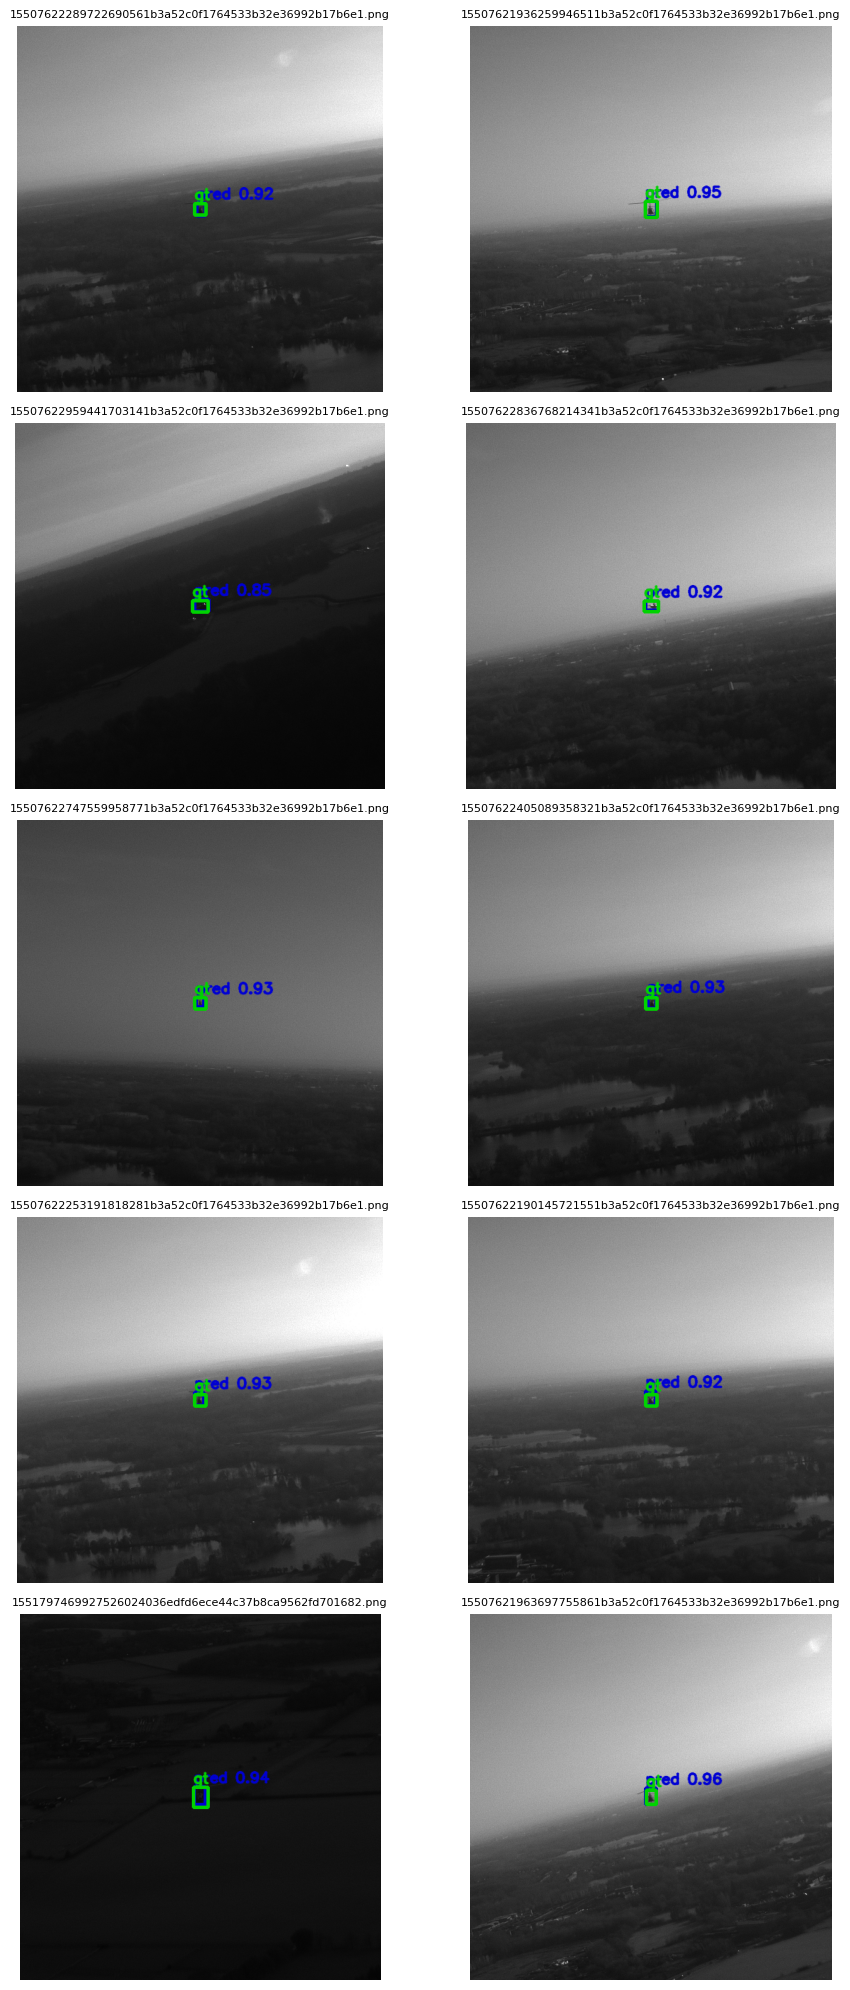

In [11]:
# Set Visualisations Folder Path. 
VISUALISER_DIR = os.path.join(RESULTS_DIR, run_name, "visualisations")

# Make & Save the Model Prediction Overlay Pictures.
visualise_results(
  results_csv = os.path.join(EVAL_RESULT_DIR, "result.csv"),
  groundtruth_csv = os.path.join(EVAL_GT_DIR, "groundtruth.csv"),
  images_dir = EVAL_DATA_DIR,
  output_dir = VISUALISER_DIR
)

# Get Image Files (Sorted for Consistency).
image_files = sorted([f for f in os.listdir(VISUALISER_DIR) if f.endswith(".png")])

# Limit the Number of Images to 10 to Fit a Grid of 2 Columns by 5 Rows.
image_files = image_files[:10]
cols = 2
rows = 5

# Create a Matplotlib Figure with the Specified Grid Size & Figure Dimensions.
fig, axes = plt.subplots(rows, cols, figsize=(10, 20))

# Iterate Over each Subplot Axis & Corresponding Image Index.
for i, ax in enumerate(axes.flatten()):
    if i < len(image_files):
        # Build the Full Image Path.
        img_path = os.path.join(VISUALISER_DIR, image_files[i])
        
        # Read + Convert BGR --> RGB.
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Display the Image in the Current Subplot.
        ax.imshow(img)

        # Clean Up the Image Filename to Show a Simpler Title.
        clean_name = image_files[i].split('_', 2)[-1]
        ax.set_title(clean_name, fontsize=8)

        # Hide the Axis Ticks & Labels for a Cleaner Look.
        ax.axis("off")
    else:
        # If there are Fewer Images than Grid Spaces, Hide Unused Axes.
        ax.axis("off")

# Adjust Spacing Between Subplots to Prevent Overlap.
plt.tight_layout()

# Display the Grid of Images.
plt.show()


---

<br/>

## **9. Introspection Module Evaluation Results**

The following results compare the previously described introspection strategies when integrated with the HRNet-W32 Tracking-to-Detect (T2D) backbone. Performance is reported on the held-out test set (243 flights), excluding the hardened training subset used during model development. This test set comprises all remaining unseen evaluation data.

<div style="background-color:#fff8dc; border-left:5px solid #f0c419; padding:12px 16px; margin:10px 0;">
<strong>⚠️ PLACEHOLDER - Results Pending Final Inference Runs.</strong><br/>
Populate this table after all introspection modules have been evaluated across the all datasets and the corresponding metrics have been collected. This represents the final stage of the introspection evaluation.
</div>

---